# Assignment: Generative Adversarial Network (GAN) {-}

This assignment aims at familiarizing you with training, validating and testing a Generative Adversarial Network (GAN). Here are the requirements of the assignment:

1.  **(5 points) Coding Tasks:** The following questions involve writing code to complete specific tasks.  
    1.1 *(1 point)* Load and process the dataset. To save training time, you only need to load and work on ONE image class of your choice.  
    1.2 *(2 points)* Build a GAN architecture consisting of at least one (01) Discriminator and one (01) Generator of which the architectures are of your choice. You are encouraged to customize the network architectures to be different from the ones demonstrated in the demo code. There are two levels of image generation requirements:
    - First-level requirement: train and generate images for ONE class of the dataset using vanilla GAN. You are free to choose which class of object you are interested in working on.
    - Second-level requirement: train and generate images for ONE class of the dataset using the mechanism of ProGAN. While strict adherence to the original paper's architecture is optional, you must maintain the core progressive training strategy (growing from low to high resolution).    

    1.3 *(1 point)* Visualize the model behaviors during the training and the validation.  
    1.4 *(1 point)* Visualize the generated images.    

2.  **(5 points) Open discussion questions:** These discussion questions ask you to analyze and argue your points.  Feel free to include relevant code examples to strengthen your arguments.  
    2.1 *(1 point)* Explain the architecture of your Generator and Discriminator. What specific layers or structures did you include, and why did you choose them?  
    2.2 *(1 point)* How does the architecture of your vanilla GAN differ from the light version of ProGAN? What changes did you make to implement the ProGAN structure?  
    2.3 *(1 point)* When working on the ProGAN, what specific issues did you face that differed from training the vanilla GAN? Did the training process improve or worsen with ProGAN?   
    2.4 *(1 point)* How did hyperparameters (e.g., learning rate, batch size) influence the performance of your GAN? Did you adjust them during training to improve results?  
    2.5 *(1 point)* What improvements would you make to your GAN or ProGAN implementation? Would you add any additional techniques or layers to improve the image generation quality?  

The dataset you will be working on is CIFAR-10. This dataset consists of 60,000 32x32 colour images in 10 classes, with 6,000 images per class. There are 50,000 training images and 10,000 test images.

Here follows some data samples in the dataset:

![alt text](cifar10.png)

### Submission {-}
The structure of submission folder should be organized as follows:

- ./\<StudentID>-assignment-GAN-notebook.ipynb: Jupyter notebook containing source code.

The submission folder is named ADL-\<StudentID>-Assignment-GAN (e.g., ADL-2012345-Assigment-GAN) and then compressed with the same name.

### Evaluation {-}
Assignment evaluation will be conducted on how you accomplish the assignment requirements. It is a plus if you have modeling steps other than the basic requirements and achieve an excellent model performance. In addition, your code should conform to a Python coding convention such as PEP-8.

### Deadline {-}
Please visit Canvas for details.

In [3]:
# Note: to enable GPU training in Colab, go to Runtime > Change runtime type > Hardware acceleration > Choose GPU from the drop-down list.

!pip install tensorflow_datasets
!pip install importlib-resources

# Import libraries
import numpy as np
import tensorflow as tf
import tensorflow_datasets as tfds
import keras
from keras import callbacks
from keras import optimizers
from keras.datasets import cifar10
from keras.layers import Dropout, Flatten, Dense, BatchNormalization
from keras import Model
from datasets import load_dataset

from sklearn.model_selection import train_test_split
from matplotlib import pyplot as plt

# First-level requirement
First-level requirement: train and generate images for ONE class of the dataset using vanilla GAN. You are free to choose which class of object you are interested in working on.

In [4]:
# 1. Load dataset from the Hugging Face UofT mirror
ds = load_dataset("uoft-cs/cifar10")

# 2. Helper function to convert Hugging Face split into NumPy arrays
def dataset_to_numpy(split):
    # Convert PIL images to NumPy arrays
    images = np.array([np.array(img) for img in split["img"]])
    labels = np.array(split["label"])
    return images, labels

X_train, y_train = dataset_to_numpy(ds["train"])
X_test, y_test = dataset_to_numpy(ds["test"])

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

# 3. Build TensorFlow tf.data.Dataset pipelines
batch_size = 64

train_dataset = (
    tf.data.Dataset.from_tensor_slices((X_train, y_train))
    .shuffle(buffer_size=10000)
    .batch(batch_size)
    .prefetch(tf.data.AUTOTUNE)
)

test_dataset = (
    tf.data.Dataset.from_tensor_slices((X_test, y_test))
    .batch(batch_size)
    .prefetch(tf.data.AUTOTUNE)
)

README.md:   0%|          | 0.00/5.16k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  120MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 23.9MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

X_train shape: (50000, 32, 32, 3)
y_train shape: (50000,)


In [5]:
# Get samples  of a certain label
label = 1 # Class '1' is car. You may change this label to another class label.
train_indices = np.where(y_train == label) # Get indices of the label
train_set = X_train[train_indices] # Get train samples of the label
test_indices = np.where(y_test == label) # Get indices of the label
test_set = X_train[test_indices] # Get test samples of the label

# Print shapes of datasets of the selected class
print("train_set shape of the selected class: " + str(train_set.shape))
print("test_set shape of the selected class: " + str(test_set.shape))

# NOTE: training a GAN does not require to have train/test split. All data samples of the training and the test set are used as real data samples.
# You should merge the training and the test set to get more real data samples, i.e., merge the train_set and the test_set to one dataset which is the real dataset.

train_set shape of the selected class: (5000, 32, 32, 3)
test_set shape of the selected class: (1000, 32, 32, 3)


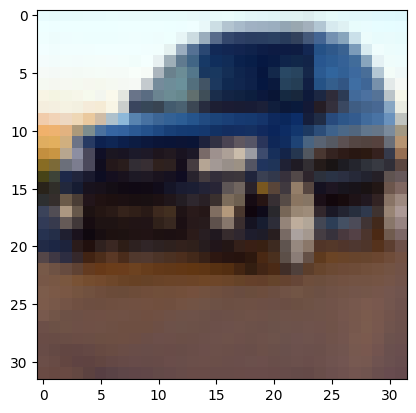

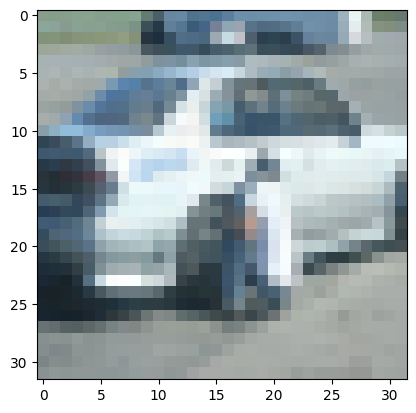

In [6]:
# Visualize some data samples of class '1' (car)
import matplotlib.pyplot as plt
imgplot = plt.imshow(train_set[0])
plt.show()
imgplot = plt.imshow(train_set[1])
plt.show()

## 1. Coding tasks

In [ ]:
# Your code goes here
# 1.1

In [ ]:
# Your code goes here
# 1.2

In [ ]:
# Your code goes here
# 1.3

In [ ]:
# Your code goes here
# 1.4

## 2. Open discussion questions

In [ ]:
# Your argument goes here
# 2.1

In [ ]:
# Your argument goes here
# 2.2

In [ ]:
# Your argument goes here
# 2.3

In [ ]:
# Your argument goes here
# 2.4

In [ ]:
# Your argument goes here
# 2.5